# Read in data

Import your packages

In [1]:
import Pkg
# This installs only the modern, compatible versions
Pkg.add(["DataFrames", "CSV", "InlineStrings", "Plots",
"Colors","StatsPlots", "Statistics", "XLSX", "Dates", "StatsBase", 
"CategoricalArrays", "Missings", "Chain", "FreqTables", "Glob", "LoggingExtras", "IJulia", "Parquet2"])


    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`


In [2]:
using DataFrames, CSV, Statistics, Dates, Logging, Parquet2, Glob
using Plots, StatsPlots, DataFrames, StatsBase, Dates, Printf, Colors, PyPlot
using DecisionTree, XGBoost
using Base.Threads
using Printf, StatsBase, Plots, StatsPlots, Statistics

Read in your file

In [4]:
parquet_file = "../../data/2_ready_for_EDA/contracts_prime_award_summaries_2010_2025.parquet"
mapping_file = "../../data/2_ready_for_EDA/metadata/headers/desired-headers-from-fy2025-0402026.csv"
# Load the parquet file
# ds = Parquet2.Dataset(parquet_file)


"../../data/2_ready_for_EDA/metadata/headers/desired-headers-from-fy2025-0402026.csv"

In [5]:
function parquet_to_df(parquet_path::String, mapping_csv_path::String)
    mapping_df = CSV.read(mapping_csv_path, DataFrame)
    target_cols = [
        string(row.variable)
        for row in eachrow(mapping_df)
        if lowercase(strip(string(row."keep?"))) == "yes"
    ]

    ds = Parquet2.Dataset(parquet_path)
    available = string.(names(ds))
    
    skip = Set(["primary_place_of_performance_county_name", "recipient_name"])
    final_cols = [c for c in intersect(target_cols, available) if !(c in skip)]
    
    println("✅ Loading $(length(final_cols)) columns individually...")
    
    cols = Dict{String, Any}()
    for col in final_cols
        try
            cols[col] = Parquet2.load(ds, col)
        catch e
            @warn "Skipping '$col': $e"
        end
    end
    
    return DataFrame(cols)
end

df = parquet_to_df(parquet_file, mapping_file)

✅ Loading 75 columns individually...


Row,award_or_idv_flag,award_type_code,awarding_office_code,c8a_program_participant,cage_code,clinger_cohen_act_planning_code,commercial_item_acquisition_procedures_code,consolidated_contract_code,construction_wage_rate_requirements_code,contingency_humanitarian_or_peacekeeping_operation_code,contract_award_unique_key,contract_bundling_code,contract_financing_code,contracting_officers_determination_of_business_size_code,corporate_entity_not_tax_exempt,cost_accounting_standards_clause_code,cost_or_pricing_data_code,country_of_product_or_service_origin_code,dod_acquisition_program_code,dod_claimant_program_code,domestic_or_foreign_entity_code,dot_certified_disadvantage,epa_designated_product_code,evaluated_preference_code,extent_competed_code,fair_opportunity_limited_sources_code,fed_biz_opps_code,for_profit_organization,foreign_funding,funding_agency_code,funding_office_code,funding_sub_agency_code,government_furnished_property_code,historically_underutilized_business_zone_hubzone_firm,information_technology_commercial_item_category_code,inherently_governmental_functions,interagency_contracting_authority_code,labor_standards_code,limited_liability_corporation,manufacturer_of_goods,materials_supplies_articles_equipment_code,minority_owned_business,multi_year_contract_code,naics_code,number_of_actions,number_of_offers_received,object_classes_funding_this_award,organizational_type,other_than_full_and_open_competition_code,parent_award_agency_id,parent_award_single_or_multiple_code,parent_award_type_code,partnership_or_limited_liability_partnership,performance_based_service_acquisition_code,period_of_performance_potential_end_date,period_of_performance_start_date,place_of_manufacture_code,potential_total_value_of_award,primary_place_of_performance_country_code,product_or_service_code,program_activities_funding_this_award,purchase_card_as_payment_method_code,recipient_parent_uei,recipient_uei,recovered_materials_sustainability_code,self_certified_small_disadvantaged_business,solicitation_date,solicitation_procedures_code,subchapter_scorporation,subcontracting_plan_code,type_of_contract_pricing_code,type_of_set_aside_code,veteran_owned_business,woman_owned_business,women_owned_small_business
,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?
1,AWARD,C,FA3016,f,1MN13,N,D,N,X,X,CONT_AWD_0001_9700_DADA1099D0053_9700,D,Z,O,f,X,N,USA,000,C2,missing,f,E,NONE,A,FAIR,Y,f,X,097,F2MRAA,5700,N,f,Z,missing,X,Y,f,f,X,f,N,221122,1,9,missing,missing,missing,9700,M,B,f,N,2024-09-30 00:00:00,2000-07-27,C,55321569.67,USA,B543,missing,N,XEQ3L57D2J24,RXNUR4G46NG3,missing,f,missing,MAFO,f,C,J,NONE,f,f,f
2,AWARD,C,FA8771,t,missing,N: NO,D,N,X,missing,CONT_AWD_0001_9700_F0162099D0006_9700,D,Z,S,f,X,N,USA,missing,S1,missing,f,E,NONE,A,FAIR,Y,f,missing,097,FA8771,5700,N,f,Z,missing,X,N,f,f,X,f,N,541511,1,12,missing,missing,missing,9700,missing,missing,f,N,2010-02-25 00:00:00,2000-02-07,C,missing,USA,D314,missing,N,GB4LSAFPM513,GB4LSAFPM513,C,t,missing,MAFO,f,B,Z,NONE,f,f,f
3,AWARD,C,FA8806,f,9N030,N,D,N,X,X,CONT_AWD_0001_9700_F0470102D0006_9700,D,Z,O,t,X,N,USA,GYY,A7,A,f,E,NONE,A,missing,Y,t,X,097,F2TS3A,5700,N,f,Z,missing,X,X,f,f,Y,f,N,541330,1,3,missing,CORPORATE NOT TAX EXEMPT,missing,9700,S,B,f,Y,2009-04-30 00:00:00,2001-12-21,C,0.00,USA,R425,missing,N,VJ3XVZC76HT9,L693MQDFLKD1,C,f,missing,NP,f,D,R,NONE,f,f,f
4,AWARD,C,FA8651,f,missing,N: NO,D,N,X,X,CONT_AWD_0001_9700_F0863003D0103_9700,D,Z,O,f,X,N,NAN,3000,A5,missi

In [5]:
stats_df = describe(df, :eltype, :nmissing, :nunique, :min, :max, :median, :mean, :std)
#CSV.write("stats-2010-2025-may6.csv", stats_df, transform=(col, val) -> something(val, missing)) 

Row,variable,eltype,nmissing,nunique,min,max,median,mean,std
,Symbol,Union,Int64,Int64,String,String,Nothing,Nothing,Nothing
1,award_or_idv_flag,"Union{Missing, String}",1,2,AWARD,IDV,,,
2,award_type_code,"Union{Missing, String}",33340,4,A,D,,,
3,awarding_office_code,"Union{Missing, String}",0,404,F38604,FY2333,,,
4,c8a_program_participant,"Union{Missing, String}",1,2,f,t,,,
5,cage_code,"Union{Missing, String}",453798,29993,0006W,ZV221,,,
6,clinger_cohen_act_planning_code,"Union{Missing, String}",42,5,:,Y: YES,,,
7,commercial_item_acquisition_procedures_code,"Union{Missing, String}",2956,5,A,E,,,
8,consolidated_contract_code,"Union{Missing, String}",18,6,A,Y,,,
9,construction_wage_rate_requirements_code,"Union{Missing, String}",7,3,N,Y,,,


In [6]:
shape = size(df)
println("The dataset has $(shape[1]) rows and $(shape[2]) columns.")

The dataset has 745848 rows and 75 columns.


# DATA PREPARATION

## Select desireable columns 
- Keeps only valuable columns defined in headers csv (contextual elimination) from 273-->82
<div class="alert alert-info">
<b>Note:</b> dataframe is called <b> df_clean</b> after this step.
</div>
using DataFrames, CSV, Dates, Statistics

In [7]:
# REMOVES UNWANTED COLUMNS
# i think this step is duplicate / no longer needed since we only load the columns we want in the first place, but keeping it here for now just in case

# Load mapping file once
mapping_df = CSV.read("../../data/2_ready_for_EDA/metadata/headers/desired-headers-from-fy2025-0402026.csv", DataFrame)
# Filter for "yes" columns and create a Map for the types

# We build a dictionary where Column Name => Ideal Type
active_mapping = filter(row -> lowercase(strip(string(row."keep?"))) == "yes", mapping_df)
type_map = Dict(string(r.variable) => lowercase(strip(string(r["ideal type"]))) for r in eachrow(active_mapping))

# Get only the columns that actually exist in your data to prevent crashes
existing_cols = names(df)
target_cols = collect(intersect(keys(type_map), existing_cols))

# Create df_clean with only the columns we want
df_desired_columns = select(df, target_cols);
vscodedisplay(df_desired_columns)


## Eliminate duplicates
- there are just duplicate entreis wehre all other values are the same
- merge on award id, and if there are conflicts, use the mode

In [8]:
# Find a duplicate contract_unique_key
dup_key = df_desired_columns |>
    x -> groupby(x, :contract_award_unique_key) |>
    x -> combine(x, nrow => :count) |>
    x -> filter(:count => >(1), x) |>
    x -> first(x.contract_award_unique_key)

# Show all rows with that key
filter(:contract_award_unique_key => ==(dup_key), df_desired_columns)

Row,funding_sub_agency_code,organizational_type,commercial_item_acquisition_procedures_code,minority_owned_business,potential_total_value_of_award,parent_award_agency_id,period_of_performance_start_date,award_type_code,clinger_cohen_act_planning_code,awarding_office_code,construction_wage_rate_requirements_code,type_of_set_aside_code,other_than_full_and_open_competition_code,funding_office_code,purchase_card_as_payment_method_code,interagency_contracting_authority_code,contract_financing_code,labor_standards_code,cost_accounting_standards_clause_code,number_of_offers_received,recipient_uei,contract_bundling_code,performance_based_service_acquisition_code,evaluated_preference_code,funding_agency_code,fair_opportunity_limited_sources_code,woman_owned_business,extent_competed_code,program_activities_funding_this_award,subcontracting_plan_code,contracting_officers_determination_of_business_size_code,inherently_governmental_functions,partnership_or_limited_liability_partnership,object_classes_funding_this_award,information_technology_commercial_item_category_code,domestic_or_foreign_entity_code,naics_code,solicitation_date,self_certified_small_disadvantaged_business,women_owned_small_business,fed_biz_opps_code,product_or_service_code,primary_place_of_performance_country_code,solicitation_procedures_code,contingency_humanitarian_or_peacekeeping_operation_code,type_of_contract_pricing_code,dot_certified_disadvantage,subchapter_scorporation,multi_year_contract_code,parent_award_single_or_multiple_code,cost_or_pricing_data_code,dod_acquisition_program_code,epa_designated_product_code,parent_award_type_code,government_furnished_property_code,number_of_actions,veteran_owned_business,limited_liability_corporation,c8a_program_participant,manufacturer_of_goods,contract_award_unique_key,foreign_funding,place_of_manufacture_code,recovered_materials_sustainability_code,dod_claimant_program_code,historically_underutilized_business_zone_hubzone_firm,award_or_idv_flag,cage_code,consolidated_contract_code,corporate_entity_not_tax_exempt,materials_supplies_articles_equipment_code,country_of_product_or_service_origin_code,period_of_performance_potential_end_date,for_profit_organization,recipient_parent_uei
,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?,String?
1,5700,missing,D,f,55321569.67,9700,2000-07-27,C,N,FA3016,X,NONE,missing,F2MRAA,N,X,Z,Y,X,9,RXNUR4G46NG3,D,N,NONE,097,FAIR,f,A,missing,C,O,missing,f,missing,Z,missing,221122,missing,f,f,Y,B543,USA,MAFO,X,J,f,f,N,M,N,000,E,B,N,1,f,f,f,f,CONT_AWD_0001_9700_DADA1099D0053_9700,X,C,missing,C2,f,AWARD,1MN13,N,f,X,USA,2024-09-30 00:00:00,f,XEQ3L57D2J24
2,5700,missing,D,f,55321569.67,9700,2000-07-27,C,N,FA3016,X,NONE,missing,F2MRAA,N,X,Z,Y,X,9,RXNUR4G46NG3,D,N,NONE,097,FAIR,f,A,missing,C,O,missing,f,missing,Z,missing,221122,missing,f,f,Y,B543,USA,MAFO,X,J,f,f,N,M,N,000,E,B,N,1,f,f,f,f,CONT_AWD_0001_9700_DADA1099D0053_9700,X,C,missing,C2,f,AWARD,1MN13,N,f,X,USA,2024-09-30 00:00:00,f,XEQ3L57D2J24
3,5700,missing,D,f,55321569.67,9700,2000-07-27,C,N,FA3016,X,NONE,missing,F2MRAA,N,X,Z,Y,X,9,RXNUR4G46NG3,D,N,NONE,097,FAIR,f,A,missing,C,O,missing,f,missing,Z,missing,221122,missing,f,f,Y,B543,USA,MAFO,X,J,f,f,N,M,N,000,E,B,N,1,f,f,f,f,CONT_AWD_0001_9700_DADA1099D0053_9700,X,C,missing,C2,f,AWARD,1MN13,N,f,X,USA,2024-09-30 00:00:00,f,XEQ3L57D2J24
4,5700,missing,D,f,55321569.67,9700,2000-07-27,C,N,FA3016,X,NONE,missing,F2MRAA,N,X,Z,Y,X,9,RXNUR4G46NG3,D,N,NONE,097,FAIR,f,A,missi

In [9]:
using DataFrames, StatsBase

function collapse_by_mode_optimized(df, group_keys)
    # 1. Identify columns to aggregate
    key_strings = group_keys isa Vector ? string.(group_keys) : [string(group_keys)]
    target_cols = setdiff(names(df), key_strings)
    
    # 2. Optimized Arbitrator
    # Using 'skipmissing' inside the function is essential.
    # We use a ternary operator for speed.
    function get_mode(x)
        clean_vals = collect(skipmissing(x))
        return isempty(clean_vals) ? missing : mode(clean_vals)
    end

    # 3. Use broadcasting (.=>) to apply the mode to every target column simultaneously
    # This is the fastest way to perform multi-column aggregation in DataFrames.jl
    df_collapsed = combine(groupby(df, group_keys), 
        target_cols .=> get_mode .=> target_cols
    )
    return df_collapsed
end
my_keys = [:contract_award_unique_key]
df_collapsed = collapse_by_mode_optimized(df_desired_columns, my_keys);
shape = size(df_collapsed)

(628590, 75)

## Assign datatypes

In [10]:
using Dates

# 1. Define specific helper functions for each type
# These are 'inlineable' and type-stable for the compiler
function to_int(x)
    (ismissing(x) || x == "") && return missing
    val = tryparse(Float64, string(x))
    return isnothing(val) ? missing : Int(round(val))
end

function to_float(x)
    (ismissing(x) || x == "") && return missing
    return tryparse(Float64, string(x))
end

function to_bool(x)
    (ismissing(x) || x == "") && return missing
    s = lowercase(strip(string(x)))
    s in ("true", "t", "y", "yes", "1", "1.0", "s") && return true
    s in ("false", "f", "n", "no", "0", "0.0", "o", "x") && return false
    return missing
end

# Pre-compile the date formats once as a constant
const DATE_FMTS = (dateformat"yyyy-mm-dd", dateformat"mm/dd/yyyy", dateformat"dd/mm/yyyy", dateformat"yyyy/mm/dd")

function to_date(x)
    (ismissing(x) || x == "") && return missing
    s = strip(string(x))
    
    # Try predefined formats
    for fmt in DATE_FMTS
        d = tryparse(Date, s, fmt)
        !isnothing(d) && return d
    end
    
    # Fallback for ISO substrings
    if length(s) >= 10
        d_sub = tryparse(Date, s[1:10])
        !isnothing(d_sub) && return d_sub
    end
    
    return missing
end

# 2. The main dispatcher function
function safe_convert!(df::DataFrame, col::Symbol, target::String)
    if target == "int"
        df[!, col] = to_int.(df[!, col])
    elseif target == "float"
        df[!, col] = to_float.(df[!, col])
    elseif target == "bool"
        df[!, col] = to_bool.(df[!, col])
    elseif target == "date"
        df[!, col] = to_date.(df[!, col])
    elseif target in ("str", "string")
        df[!, col] = ifelse.(ismissing.(df[!, col]), missing, string.(df[!, col]))
    end
    return df
end

# 3. Usage in your loop
for col_name in target_cols
    ideal = type_map[string(col_name)]
    safe_convert!(df_collapsed, Symbol(col_name), ideal)
end
show(describe(df_collapsed, :eltype, :nmissing), allrows=true)

75×3 DataFrame
 Row │ variable                           eltype                   nmissing 
     │ Symbol                             Type                     Int64    
─────┼──────────────────────────────────────────────────────────────────────
   1 │ contract_award_unique_key          String                          0
   2 │ funding_sub_agency_code            Union{Missing, String}       1072
   3 │ organizational_type                Union{Missing, String}     252437
   4 │ commercial_item_acquisition_proc…  Union{Missing, String}       2880
   5 │ minority_owned_business            Union{Missing, Bool}            1
   6 │ potential_total_value_of_award     Union{Missing, Float64}    177822
   7 │ parent_award_agency_id             Union{Missing, String}     227486
   8 │ period_of_performance_start_date   Union{Missing, Date}            2
   9 │ award_type_code                    Union{Missing, String}      22873
  10 │ clinger_cohen_act_planning_code    Union{Missing, Bool}       1

## Remove Date Columns and replace with duration columns

In [ ]:
function add_duration_features!(df::AbstractDataFrame)

    function get_median_days(duration_vec)
        clean_days = [d.value for d in skipmissing(duration_vec)]
        return isempty(clean_days) ? 0 : round(Int, median(clean_days))
    end

    # 1. potential_length_of_performance (end, start)
    perf_diff = df.period_of_performance_potential_end_date .- df.period_of_performance_start_date
    m_perf = get_median_days(perf_diff)
    df[!, :potential_length_of_performance] = [ismissing(d) ? m_perf : d.value for d in perf_diff]

    # 2. solicitation_to_start_date + missingness indicator (start, solicitation)
    solic_diff = df.period_of_performance_start_date .- df.solicitation_date
    m_solic = get_median_days(solic_diff)
    df[!, :solicitation_to_start_date_missing] = Int.(ismissing.(solic_diff))  # indicator
    df[!, :solicitation_to_start_date] = [ismissing(d) ? m_solic : d.value for d in solic_diff]

    # 3. start year — passmissing handles missing dates safely
    df[!, :performance_start_year] = passmissing(Dates.year).(df.period_of_performance_start_date)
    # then fill missing years with median or a sentinel
    m_year = round(Int, median(skipmissing(df[!, :performance_start_year])))
    df[!, :performance_start_year] = coalesce.(df[!, :performance_start_year], m_year)

    select!(df, Not([:period_of_performance_start_date, 
                     :period_of_performance_potential_end_date, 
                     :solicitation_date]))
    return df
end

df_with_dates = copy(df_collapsed)
df_with_dates= add_duration_features!(df_with_dates)
size(df_with_dates)

(628590, 76)

## Deal with Missing Values

### Tailored

In [12]:
df_clean = copy(df_with_dates)

# This creates a new DataFrame with ONLY rows that have an award_amount
df_clean= dropmissing(df_with_dates, :potential_total_value_of_award)

# remove rows with negative award amounts
df_clean = filter(row -> row.potential_total_value_of_award > 0, df_clean)

# 2. parent_award_agency_id — fill missing with sentinel, add binary flag
df_clean.parent_award_agency_id = coalesce.(df_clean.parent_award_agency_id, "MISSING_AGENCY_ID")

# 3. primary_place_of_performance_zip_5 — fill with sentinel
df_clean.type_of_set_aside_code = coalesce.(df_clean.type_of_set_aside_code, "00000")

# 4. contract_description — fill with empty string
df_clean.program_activities_funding_this_award = coalesce.(df_clean.program_activities_funding_this_award, "")
df_clean.object_classes_funding_this_award = coalesce.(df_clean.object_classes_funding_this_award, "")

# 6. fill missings with false
df_clean.multi_year_contract_code = coalesce.(df_clean.multi_year_contract_code, false)

# 7. fill cost_or_pricing_code with false
df_clean.cost_or_pricing_data_code = coalesce.(df_clean.cost_or_pricing_data_code, false)

# 8. fill parent_award_type_code with "UNKNOWN"
df_clean.parent_award_type_code = coalesce.(df_clean.parent_award_type_code, "UNK")

# 9. fill other_than_full_and_open_competition_code with "UNK"
df_clean.other_than_full_and_open_competition_code = coalesce.(df_clean.other_than_full_and_open_competition_code, "UNK")

# 10. fill cost_accounting_standards_clause_code with "X"
df_clean.cost_accounting_standards_clause_code = coalesce.(df_clean.cost_accounting_standards_clause_code, "X")

# 11. Fill parent_award_single_or_multiple_code with "UNK"
df_clean.parent_award_single_or_multiple_code = coalesce.(df_clean.parent_award_single_or_multiple_code, "UNK")

# 12. fill inherently_governmental_functions with "OT"
df_clean.inherently_governmental_functions = coalesce.(df_clean.inherently_governmental_functions, "OT")

# 13. fill fair_opportunity_limited_code with "UNK"
df_clean.fair_opportunity_limited_sources_code = coalesce.(df_clean.fair_opportunity_limited_sources_code, "UNK")

# 14. fill subcontracting_plan_code with "B"
df_clean.subcontracting_plan_code = coalesce.(df_clean.subcontracting_plan_code, "B")

# Verify no remaining missings
println(describe(df_clean, :nmissing))

println("Rows remaining: ", nrow(df_clean))

76×2 DataFrame
 Row │ variable                           nmissing 
     │ Symbol                             Int64    
─────┼─────────────────────────────────────────────
   1 │ contract_award_unique_key                 0
   2 │ funding_sub_agency_code                 198
   3 │ organizational_type                   72962
   4 │ commercial_item_acquisition_proc…      2820
   5 │ minority_owned_business                   1
   6 │ potential_total_value_of_award            0
   7 │ parent_award_agency_id                    0
   8 │ award_type_code                       15087
   9 │ clinger_cohen_act_planning_code          31
  10 │ awarding_office_code                      0
  11 │ construction_wage_rate_requireme…         2
  12 │ type_of_set_aside_code                    0
  13 │ other_than_full_and_open_competi…         0
  14 │ funding_office_code                     200
  15 │ purchase_card_as_payment_method_…     15087
  16 │ interagency_contracting_authorit…         7
  17 │ contra

### General

In [13]:
using DataFrames, Statistics, InlineStrings

using DataFrames, Statistics, Missings, InlineStrings

function smart_fill!(df::DataFrame)
    for col in names(df)
        # Get the underlying type (ignoring the Union{Missing, ...})
        T = nonmissingtype(eltype(df[!, col]))
        
        # --- 1. Handle Categorical / Strings (The source of your error) ---
        if T <: AbstractString
            # CRITICAL: Convert to string first to allow "Unknown" or "Missing"
            df[!, col] = string.(df[!, col]) 
            replace!(df[!, col], missing => "UNK")
            replace!(df[!, col], "missing"=> "UNK")
            
        # --- 2. Handle Booleans ---
        elseif T == Bool
            replace!(df[!, col], missing => false)
            df[!, col] = Bool.(df[!, col]) 
            
            
        # --- 3. Handle Integers ---
        elseif T <: Integer
            replace!(df[!, col], missing => 0)
            df[!, col] = Int64.(df[!, col])
            
        # --- 4. Handle Floats ---
        elseif T <: AbstractFloat
            # Use median to avoid outliers in your density plots
            val = isempty(collect(skipmissing(df[!, col]))) ? 0.0 : median(skipmissing(df[!, col]))
            replace!(df[!, col], missing => val)
            df[!, col] = Float64.(df[!, col])

        # --- 5. Catch-all for 'Any' ---
        else
            # Force conversion to String if it's a weird mix
            df[!, col] = string.(df[!, col])
            replace!(df[!, col], "missing" => "UNK")
        end
        replace!(df[!, col], "missing" => "UNK")
    end
    df = identity.(df)
    return df
end

# Apply the fix
df_filled_missings = copy(df_clean) # Create a copy to preserve the original
df_filled_missings = smart_fill!(df_filled_missings);
println(describe(df_filled_missings, :nmissing))


76×2 DataFrame
 Row │ variable                           nmissing 
     │ Symbol                             Int64    
─────┼─────────────────────────────────────────────
   1 │ contract_award_unique_key                 0
   2 │ funding_sub_agency_code                   0
   3 │ organizational_type                       0
   4 │ commercial_item_acquisition_proc…         0
   5 │ minority_owned_business                   0
   6 │ potential_total_value_of_award            0
   7 │ parent_award_agency_id                    0
   8 │ award_type_code                           0
   9 │ clinger_cohen_act_planning_code           0
  10 │ awarding_office_code                      0
  11 │ construction_wage_rate_requireme…         0
  12 │ type_of_set_aside_code                    0
  13 │ other_than_full_and_open_competi…         0
  14 │ funding_office_code                       0
  15 │ purchase_card_as_payment_method_…         0
  16 │ interagency_contracting_authorit…         0
  17 │ contra

## Filter out IDVs
<div class="alert alert-success">
Ok so we see here that awards represent 2.8% of money but 90% of rows. This is very insightful. It means that while the majority of transactions are Awards, the bulk of the money is in IDVs because they represent the big papa bear agreements - not actual sales. So we want to filter these out!
</div>

In [14]:
using Plots, Statistics

# Compute mean and median of the original log10 target by contract type
summary_stats = combine(
    groupby(df_filled_missings, :award_or_idv_flag),
    :potential_total_value_of_award => (x -> median(skipmissing(x))) => :median_value,
    :potential_total_value_of_award => (x -> mean(skipmissing(x)))   => :mean_value,
    :potential_total_value_of_award => (x -> sum(!ismissing, x))     => :n
)
println(summary_stats)

3×4 DataFrame
 Row │ award_or_idv_flag  median_value  mean_value     n      
     │ String             Float64       Float64        Int64  
─────┼────────────────────────────────────────────────────────
   1 │ AWARD                 47550.0        2.46328e6  429517
   2 │ IDV                       4.0e6      2.26321e9   15086
   3 │ UNK                   11938.7    11938.7             1


## Plots

In [ ]:
Plots.reset_defaults()
gr()


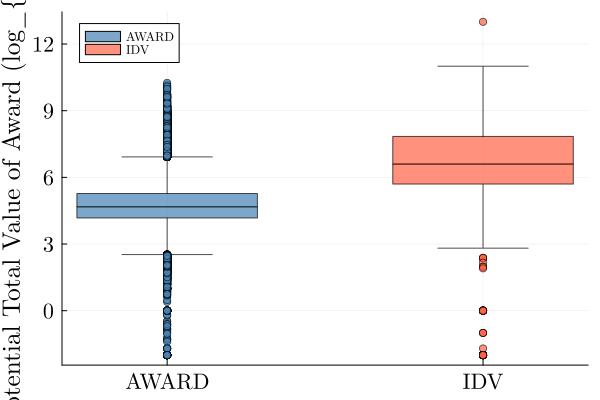

In [ ]:

awards_vals = log10.(filter(x -> x > 0, collect(skipmissing(
    df_filled_missings[df_filled_missings.award_or_idv_flag .== "AWARD", :potential_total_value_of_award]))))

idv_vals = log10.(filter(x -> x > 0, collect(skipmissing(
    df_filled_missings[df_filled_missings.award_or_idv_flag .== "IDV", :potential_total_value_of_award]))))







In [19]:
using LaTeXStrings

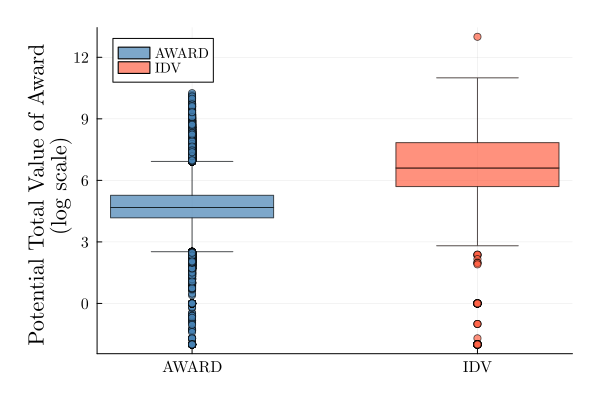

In [42]:
default(
    fontfamily = "Computer Modern",
    titlefontsize = 16,
    guidefontsize = 14,
    tickfontsize = 10,
    legendfontsize = 9)
p = StatsPlots.boxplot(["AWARD"], awards_vals, label="AWARD", color=:steelblue, alpha=0.7,
    ylabel="Potential Total Value of Award \n (log scale)", 
    legend=:topleft, fontfamily="Computer Modern", 
        left_margin=8Plots.mm, top_margin=5Plots.mm,
        bottom_margin=5Plots.mm, right_margin=5Plots.mm)
StatsPlots.boxplot!(["IDV"], idv_vals, label="IDV", color=:tomato, alpha=0.7)

display(p)

In [44]:
# # save figures
# mkpath("figures")
Plots.savefig(p, "figures/contract_value_distribution_may232026.pdf")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/ALL-COL-FINAL/figures/contract_value_distribution_may232026.pdf"

In [ ]:
award_count = count(==("AWARD"), df_filled_missings.award_or_idv_flag)
idv_count   = count(==("IDV"),   df_filled_missings.award_or_idv_flag)

award_money = sum(skipmissing(df_filled_missings[df_filled_missings.award_or_idv_flag .== "AWARD", :potential_total_value_of_award]))
idv_money   = sum(skipmissing(df_filled_missings[df_filled_missings.award_or_idv_flag .== "IDV",   :potential_total_value_of_award]))

p1 = StatsPlots.bar(["AWARD", "IDV"], [award_count, idv_count],
    color=[:steelblue, :tomato], alpha=0.8, legend=false,
    title="\n Contract Volume\n", ylabel="Count",
    bar_width=0.5,fontfamily="Computer Modern",
    titlefontsize=12, titlecolor=:grey30,
    guidefontsize=11)

p2 = StatsPlots.bar(["AWARD", "IDV"], [award_money, idv_money] ./ 1e9,
    color=[:steelblue, :tomato], alpha=0.8, legend=false,
    title="\n Total Contract Value\n", ylabel="Value (\$B)",
    bar_width=0.5, fontfamily="Computer Modern",
    titlefontsize=12, titlecolor=:grey30,
    guidefontsize=11)

    #annotate!(p, x, y, annotation)
    # where annotation: text(string, fontsize, style, halign, valign, rotation, color)
annotate!(p1, [.5, 1.5], [award_count, idv_count] .+ 0.02 .* maximum([award_count, idv_count]),
    [text(string(v), font(8, "Computer Modern"), halign=:center, :grey20) for v in [award_count, idv_count]])

annotate!(p2, [.5, 1.5], [award_money, idv_money] ./ 1e9 .+ 0.02 .* maximum([award_money, idv_money] ./ 1e9),
    [text(string(round(v, digits=1)), font(8, "Computer Modern"), halign=:center, :grey20) for v in [award_money, idv_money] ./ 1e9])

    p = plot(p1, p2, layout=(1,2), size=(900, 450),
    left_margin=10Plots.mm, top_margin=5Plots.mm,
    bottom_margin=5Plots.mm, right_margin=5Plots.mm)

# p = plot(p1, p2, layout=(1,2), size=(900, 450),
#     plot_title="AWARD vs IDV: Volume and Value Disparity",
#     plot_titlefontsize=16, fontfamily="Computer Modern",
#     left_margin=10Plots.mm, top_margin=5Plots.mm,
#     bottom_margin=5Plots.mm, right_margin=5Plots.mm)

UndefVarError: UndefVarError: `text` not defined in `Main`
Hint: It looks like two or more modules export different bindings with this name, resulting in ambiguity. Try explicitly importing it from a particular module, or qualifying the name with the module it should come from.
Hint: a global variable of this name also exists in Plots.
    - Also exported by StatsPlots.
Hint: a global variable of this name also exists in GR.
Hint: a global variable of this name also exists in PyPlot.

In [19]:
# save figure
# savefig(p, "figures/award_idv_comparison.pdf")

#### WHY FILTER? 
We are building a "Zestimate" model to predict the price of individual purchases. 

1. 'IDV' rows (9.5% of data) represent Master Agreements (the "Ceiling"). 
   They are legal frameworks, not actual sales. Their 'Potential Value' is 
   often 100x larger than an individual transaction, acting as a "Permit" 
   rather than a "Price."

2. 'AWARD' rows (90.5% of data) represent actual "Closing Prices." 
   These are the transactions where money is committed for specific work.

**STRATEGY:** 
By removing IDVs, we eliminate massive financial outliers and prevent 
the model from being "distracted" by administrative ceilings. This ensures 
Variable Importance is calculated based on real-world market prices.

In [20]:
df_model = filter(row -> isequal(row.award_or_idv_flag, "AWARD"), df_filled_missings)
select!(df_model, Not(:award_or_idv_flag)); # Remove the award column 
shape = size(df_model)

(429517, 75)

literally changed nothing but running it again and again fixed it.... what are you supposed to do with that.

# Fix categorical columns

## Roll up funding office code to two-letter

In [21]:
using DataFrames

df_model_test = copy(df_model) # Create a copy to preserve the original

# FUNDING OFFICE CODE
value_counts = combine(groupby(df_model, :funding_office_code), nrow => :count)
sort!(value_counts, :count, rev=true)
df_model_test[!, :funding_office_code] = first.(coalesce.(df_model_test[!, :funding_office_code], "00"), 2)
value_counts = combine(groupby(df_model_test, :funding_office_code), nrow => :count)
sort!(value_counts, :count, rev=true)
# Syntax: rename!(dataframe, :old_name => :new_name)
rename!(df_model_test, :funding_office_code => :funding_office_code_twoletter);

# AWARDING OFFICE CODE
value_counts = combine(groupby(df_model_test, :awarding_office_code), nrow => :count)
sort!(value_counts, :count, rev=true)
three_letter_codes = first.(df_model_test[!, :"awarding_office_code"], 3)
unique_count_3 = length(unique(three_letter_codes))
println("There are $unique_count_3 unique 3-letter divisions.")
df_model_test[!, :awarding_office_code] = first.(coalesce.(df_model_test[!, :awarding_office_code], "000"), 3)
value_counts = combine(groupby(df_model_test, :awarding_office_code), nrow => :count)
sort!(value_counts, :count, rev=true)
rename!(df_model_test, :awarding_office_code => :awarding_office_code_threeletter);

There are 10 unique 3-letter divisions.


## Roll Up NAICS Code

In [22]:
# 1. Group and Count
value_counts = combine(groupby(df_model_test, :naics_code), nrow => :count)

# 2. Sort by count (descending to see the "biggest" offices first)
sort!(value_counts, :count, rev=true);
using DataFrames

# Assuming your column is :naics_code and it might be stored as an Integer or String.
# We convert to string first to ensure we can use 'first' reliably.
naics_str = string.(df_model_test.naics_code)

summary = DataFrame(
    Digits = [2, 3, 4, 5],
    Unique_Count = [
        length(unique(first.(naics_str, 2))),
        length(unique(first.(naics_str, 3))),
        length(unique(first.(naics_str, 4))),
        length(unique(first.(naics_str, 5)))
    ]
)

println(summary)

4×2 DataFrame
 Row │ Digits  Unique_Count 
     │ Int64   Int64        
─────┼──────────────────────
   1 │      2            25
   2 │      3           107
   3 │      4           309
   4 │      5           641


Going to choose 2 digit to capture sector (i have definitions for these)

In [23]:
two_letter_codes = passmissing(first).(df_model_test[!, :"naics_code"], 2)
# Use the '!' symbol to update the column directly in your dataframe
df_model_test[!, :naics_code] = passmissing(first).(df_model_test[!, :naics_code], 2)
value_counts = combine(groupby(df_model_test, :naics_code), nrow => :count)
sort!(value_counts, :count, rev=true)
# Syntax: rename!(dataframe, :old_name => :new_name)
rename!(df_model_test, :naics_code => :naics_code_sector);

## Roll up more codes contextually
1) product or service cod
2) contract pricing code
3) set aside code
4) parent_award_id


In [24]:
using CSV
using DataFrames
using Glob

function apply_mappers_optimized!(df::DataFrame, mapper_folder::String)
    mapper_files = glob("*.csv", mapper_folder)
    
    for file in mapper_files
        # Use 'stringtype=String' to ensure consistency
        mapping_df = CSV.read(file, DataFrame, stringtype=String)
        
        old_col_name = names(mapping_df)[1]
        new_col_name = names(mapping_df)[2]
        
        # Safety Sync: Force both 'key' columns to String and strip whitespace
        # This prevents the "300" (Int) vs "300" (String) mismatch
        df[!, Symbol(old_col_name)] = [ismissing(x) ? missing : strip(string(x)) for x in df[!, Symbol(old_col_name)]]
        mapping_df[!, 1] = [ismissing(x) ? missing : strip(string(x)) for x in mapping_df[!, 1]]
        

        # 2. Prepare the mapper for the join
        # We rename the columns to match your desired 'New Column' name
        temp_map = rename(mapping_df, 1 => old_col_name, 2 => new_col_name)
        
        # 3. Perform the join
        # matchmissing=:notequal prevents the error when your main data has holes
        allowmissing!(temp_map, old_col_name)
        leftjoin!(df, temp_map, on = old_col_name, matchmissing = :notequal)
        
        df[!, Symbol(new_col_name)] = coalesce.(df[!, Symbol(new_col_name)], "Unknown")
        select!(df, Not(Symbol(old_col_name)))
        
        println("Processed: $old_col_name into $new_col_name")
    end
    
    return df
end

df_model1 = copy(df_model_test) # Create a copy to preserve the original
df_model1 = apply_mappers_optimized!(df_model1, "../../data/2_ready_for_EDA/metadata/mappers/"); # Apply all mappers in the folder
shape = size(df_model1)

Processed: parent_award_agency_id into parent_award_group
Processed: product_or_service_code into psc_group
Processed: type_of_contract_pricing_code into contract_pricing_group
Processed: type_of_set_aside_code into set_aside_group


(429517, 75)

In [48]:
#sort column names alphabetically
sorted_cols = sort(names(df_model1))
df_model1 = select(df_model1, sorted_cols);
vscodedisplay(df_model1)

In [47]:
vscodedisplay(df_model1)

## Fix rows with aggregate entries
</div>
<div class="alert alert-info">
<b>Note:</b> dataframe is called <b>df_model2</b> after this step
</div>

ordered by funding dollars so we just take the first one!

In [49]:
using DataFrames

agg_cols = [:program_activities_funding_this_award, :object_classes_funding_this_award]

# Count rows where at least one of the agg_cols contains a semicolon
num_agg_rows = count(eachrow(df_model1)) do row
    any(agg_cols) do col
        val = row[col]
        # Check if value is not missing and contains the semicolon
        # We use string(val) to safely handle any non-string data types
        !ismissing(val) && occursin(";", string(val))
    end
end

println("Total rows with aggregate information: $num_agg_rows")
# 1. Define the efficient extractor
clean_split(s) = ismissing(s) ? missing : (idx = findfirst(';', s); isnothing(idx) ? s : s[1:prevind(s, idx)])

# 2. Apply to all columns in your list
agg_cols = [:program_activities_funding_this_award]
df_model2 = copy(df_model1) # Create a copy to preserve the original
transform!(df_model2, agg_cols .=> ByRow(clean_split) .=> agg_cols);

Total rows with aggregate information: 12346


# Row manipulation after fixing data

## Variance Analysis - identifies columns with high frequency of unique values (if one value has 99% frequency)
</div>
<div class="alert alert-info">
<b>Note:</b> dataframe is called <b>df_post_variance</b> after this step
</div>

In [50]:
using DataFrames, StatsBase, CSV

function variance_analysis_audit(df, filename="data_variance_audit-$(now()).csv"; save_csv=true)
    results = DataFrame(
        column = String[], 
        unique_values = Int[], 
        most_frequent_pct = Float64[], 
        top_value = Any[],
        recommendation = String[]
    )
    
    for col in names(df)
        data = collect(skipmissing(df[!, col]))
        
        if isempty(data)
            push!(results, (col, 0, 100.0, "EMPTY", "DROP: No data"))
            continue
        end
        
        counts = countmap(data)
        top_val = argmax(counts)
        top_pct = (counts[top_val] / length(data)) * 100
        unique_count = length(counts)
        
        # Automatic Recommendation Logic
        rec = "KEEP"
        if top_pct > 99.5
            rec = "DROP: Constant (>99.5%)"
        elseif unique_count == 1
            rec = "DROP: Single Value"
        elseif unique_count > (nrow(df) * 0.9)
            rec = "CAUTION: Likely ID/Unique Key"
        end
        
        push!(results, (col, unique_count, round(top_pct, digits=2), string(top_val), rec))
    end
    
    sort!(results, :most_frequent_pct, rev=true)
    
    if save_csv
        # Export to CSV so you can open it in Excel/Sheets
        CSV.write(filename, results)
        println("Audit complete! Open '$filename' to review.")
    else
        println("Audit complete! Results returned (CSV export skipped).")
    end
    
    return results
end

# Run it
audit_df = variance_analysis_audit(df_model2, save_csv=false);
# 1. Define your threshold (Industry standard is usually 99% to 99.9%)
threshold = 95

# 2. Identify the "Death List" from your audit table
death_list = audit_df[audit_df.most_frequent_pct .> threshold, :column]

# 3. Filter the list to make sure you don't accidentally drop your target price!
# Replace 'potential_total_value_of_award' with your actual target column name
death_list = filter(x -> x != "potential_total_value_of_award", death_list)

println("Removing $(length(death_list)) columns with near-zero variance...")
println("Columns being dropped: ", death_list)

# 4. Perform the mass deletion
df_post_variance = select(df_model2, Not(death_list))

# 5. Final Check
println("New column count: ", ncol(df_post_variance))

Audit complete! Results returned (CSV export skipped).
Removing 12 columns with near-zero variance...
Columns being dropped: ["funding_agency_code", "evaluated_preference_code", "interagency_contracting_authority_code", "multi_year_contract_code", "foreign_funding", "dod_acquisition_program_code", "inherently_governmental_functions", "government_furnished_property_code", "funding_sub_agency_code", "clinger_cohen_act_planning_code", "materials_supplies_articles_equipment_code", "contract_pricing_group"]
New column count: 63


## Numerical Columns Analysis


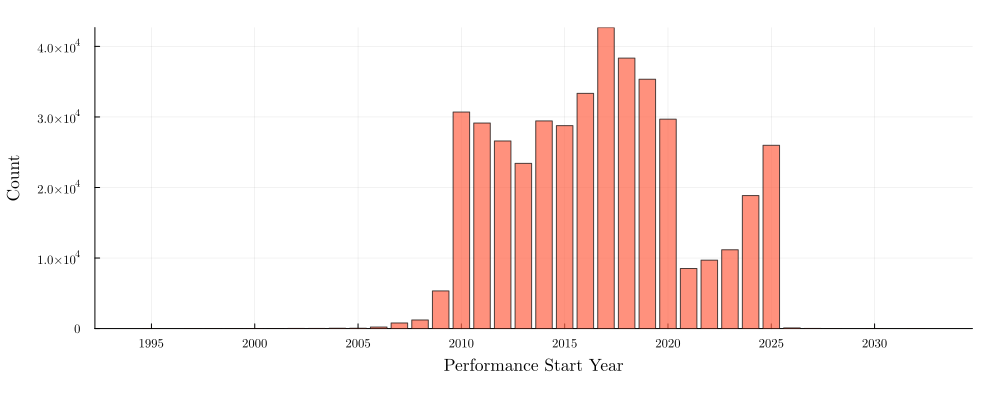

In [51]:
# convert number_of_actions to integer 
# df_post_variance[!, :number_of_actions] = passmissing(x -> parse(Int, x)).(df_post_variance.number_of_actions);
year_counts = combine(groupby(df_post_variance, :performance_start_year), nrow => :count)
sort!(year_counts, :performance_start_year)

p = StatsPlots.bar(year_counts.performance_start_year, year_counts.count,
    xlabel = "Performance Start Year",
    ylabel = "Count",
    label = false,
    color = :tomato,
    alpha = 0.7,
    size = (1000, 400),
    xticks = (minimum(year_counts.performance_start_year):5:maximum(year_counts.performance_start_year), 
              string.(minimum(year_counts.performance_start_year):5:maximum(year_counts.performance_start_year))),
    xrotation = 0,
    left_margin=5Plots.mm, top_margin=5Plots.mm,
    bottom_margin=10Plots.mm, right_margin=5Plots.mm,
    )


    display(p)

In [52]:
# savefig(p, "figures/awards_by_start_year.pdf")

In [53]:
# Define which columns get which cutoff
target_cols = Dict(
    :number_of_offers_received        => 0.99,
    :number_of_actions               => 0.99,
    :potential_length_of_performance => 0.99,
    :solicitation_to_start_date      => 0.99,
    :potential_total_value_of_award  => 0.99
)

describe(df_post_variance[!, collect(keys(target_cols))], :mean, :std, :min, :q25, :median, :q75, :max, :nmissing)

Row,variable,mean,std,min,q25,median,q75,max,nmissing
,Symbol,Union…,Union…,Any,Union…,Union…,Union…,Any,Int64
1,solicitation_to_start_date,51.8251,121.222,-3632,44.0,44.0,44.0,19265,0
2,number_of_actions,,,1,,,,99,0
3,potential_length_of_performance,353.2,730.57,-1369,39.0,161.0,365.0,328808,0
4,potential_total_value_of_award,2.46328e6,7.26972e7,0.01,14892.0,47550.0,1.87386e5,1.79024e10,0
5,number_of_offers_received,7.48045,58.7889,0,1.0,2.0,3.0,999,0


In [54]:
shape = size(df_post_variance)

(429517, 63)

## High Cardinality Reduction
in this section we remove / collapse a lot of those categories using a 5% threshold (max 10 columns)
</div>
<div class="alert alert-info">
<b>Note:</b> dataframe is called <b>df_reduced_cardinality</b> after this step
</div>


In [55]:

candidates = [col for col in names(df_post_variance) if eltype(df_post_variance[!, col]) <: Union{AbstractString, Missing} && length(unique(skipmissing(df_post_variance[!, col]))) > 50]

sort!(candidates)
println("Potential columns for lumping:")
foreach(col -> println(col, " (", length(unique(skipmissing(df_post_variance[!, col]))), " unique)"), candidates)

Potential columns for lumping:
cage_code (28523 unique)
contract_award_unique_key (429517 unique)
country_of_product_or_service_origin_code (142 unique)
funding_office_code_twoletter (118 unique)
number_of_actions (357 unique)
object_classes_funding_this_award (628 unique)
primary_place_of_performance_country_code (151 unique)
program_activities_funding_this_award (101 unique)
recipient_parent_uei (45396 unique)
recipient_uei (46269 unique)


In [56]:
using StatsBase
"""
    automated_lumping!(df, columns; threshold=0.05)

Reduces high-cardinality in categorical columns by grouping values that appear 
less than the specified `threshold` (percentage) into a unique 'OTHER' category.
"""
function automated_lumping!(df::AbstractDataFrame, columns; threshold=0.05, min_keep=3)
    cols_to_fix = columns isa Symbol ? [columns] : columns
    
    for col in cols_to_fix
        df[!, col] = string.(df[!, col])
        
        # 1. Get frequencies and sort them
        counts_map = countmap(collect(skipmissing(df[!, col]))) # skip missing for counting
        sorted_counts = sort(collect(counts_map), by=x->x[2], rev=true)
        total = nrow(df)
        
        # 2. Identify who is eligible for lumping
        # Eligibility: Must NOT be in the Top N
        num_to_protect = min(min_keep, length(sorted_counts))
        protected_labels = [sorted_counts[i][1] for i in 1:num_to_protect]
        
        # 3. Identify candidates (Anything not protected AND below threshold)
        to_group = [k for (k, v) in counts_map 
                    if !(k in protected_labels) && (v / total) < threshold]
        
        if !isempty(to_group)
            new_label = "OTHER_" * uppercase(string(col))
            df[!, col] = [x in to_group ? new_label : x for x in df[!, col]]
            
            # Audit the result
            println("Fixed $col: Protected the Top $num_to_protect; lumped $(length(to_group)) rare labels.")
        else
            println("Skipped $col: All rare labels were within the Top $min_keep protected slots.")
        end
    end
end

# Explicitly define the columns you want to clean
# object_classes_funding_this_award, program_activities_funding_this_award, --> fix this first cause i will need do to this step
# recipient_parent_uei, recipient_uei --> keeping these only for merging dataset but we dont actaully need them. 
candidates = [
    :cage_code,
    :country_of_product_or_service_origin_code,
    :funding_office_code_twoletter,
    :object_classes_funding_this_award,
    :primary_place_of_performance_country_code,
    :program_activities_funding_this_award,
    :recipient_parent_uei,
    :recipient_uei]
# Make a copy to preserve the original before lumping
df_reduced_cardinality = copy(df_post_variance)

# Run the lumping function on the updated list
automated_lumping!(df_reduced_cardinality, candidates, threshold=0.05)

Fixed cage_code: Protected the Top 3; lumped 28520 rare labels.
Fixed country_of_product_or_service_origin_code: Protected the Top 3; lumped 139 rare labels.
Fixed funding_office_code_twoletter: Protected the Top 3; lumped 113 rare labels.
Fixed object_classes_funding_this_award: Protected the Top 3; lumped 625 rare labels.
Fixed primary_place_of_performance_country_code: Protected the Top 3; lumped 148 rare labels.
Fixed program_activities_funding_this_award: Protected the Top 3; lumped 98 rare labels.
Fixed recipient_parent_uei: Protected the Top 3; lumped 45393 rare labels.
Fixed recipient_uei: Protected the Top 3; lumped 46266 rare labels.


## Final column editing (distributions)

In [57]:
df_removed_poor_distros = copy(df_reduced_cardinality) # Create a copy to preserve the original before transformations
shape = size(df_removed_poor_distros)
# --- Main Transformation Logic ---

(429517, 63)

In [58]:
# 1. Commercial Item Acquisition
df_removed_poor_distros.commercial_item_acquisition_procedures_code = map(x -> begin
    ismissing(x) ? "Other" :
    x == "D" ? "D" :
    x == "A" ? "A" :
    x in ("C", "E", "B") ? "Other" : "Other"
end, df_removed_poor_distros.commercial_item_acquisition_procedures_code)

# Consolidated contract code (Y,A,B,C, UNK) --> other
df_removed_poor_distros.consolidated_contract_code = map(x -> begin
    ismissing(x) ? "Other" :
    x in ("Y", "A", "B", "C", "UNK") ? "Other" : x
end, df_removed_poor_distros.consolidated_contract_code)

# Contract bundling code (E, G, F, C) -- other
df_removed_poor_distros.contract_bundling_code = map(x -> begin
    ismissing(x) ? "Other" :
    x in ("E", "G", "F", "C") ? "Other" : x
end, df_removed_poor_distros.contract_bundling_code)

# Contract Financing Code (A, E, D, UNK, F) -- other
df_removed_poor_distros.contract_financing_code = map(x -> begin
    ismissing(x) ? "Other" :
    x in ("A", "E", "D", "UNK", "F") ? "Other" : x
end, df_removed_poor_distros.contract_financing_code)


# 2. DOD Claimant Program (Unknown -> C9E)
df_removed_poor_distros.dod_claimant_program_code = map(x -> begin
    (ismissing(x) || uppercase(string(x)) == "UNK") ? "C9E" : x
end, df_removed_poor_distros.dod_claimant_program_code)


# # type of set aside code (00000-->NONE)
# df_removed_poor_distros.type_of_set_aside_code = map(x -> begin
#     s = coalesce(x, "Unknown")
#     s == "00000" ? "NONE" : s
# end, df_removed_poor_distros.type_of_set_aside_code)

# 7. IT Commercial Item Category
df_removed_poor_distros.information_technology_commercial_item_category_code = map(x -> begin
    s = coalesce(x, "Unknown")
    s == "Z" ? "Z" :
    s in ("A", "B", "E") ? "A/B/E" : "Other"
end, df_removed_poor_distros.information_technology_commercial_item_category_code)


# 13. Place of Manufacture
df_removed_poor_distros.place_of_manufacture_code = map(x -> begin
    x == "C" ? "C" :
    x == "D" ? "D" : "Other"
end, df_removed_poor_distros.place_of_manufacture_code)


# 17. Subcontracting Plan Code
df_removed_poor_distros.subcontracting_plan_code = map(x -> begin
    s = coalesce(x, "Unknown")
    s in ("C", "D", "E") ? "Plan" :
    s in ("A", "B") ? "No Plan" : s
end, df_removed_poor_distros.subcontracting_plan_code);



In [59]:
drop_columns_list = 
[
    :cage_code,
    :recipient_uei, 
    :recipient_parent_uei,
    :contingency_humanitarian_or_peacekeeping_operation_code,
    :domestic_or_foreign_entity_code,
    :epa_designated_product_code,
    :recovered_materials_sustainability_code,
    :women_owned_small_business,
    :consolidated_contract_code,
    :contract_financing_code,
    :contract_bundling_code,
    :cost_accounting_standards_clause_code,
    :dot_certified_disadvantage,
    :object_classes_funding_this_award,
    :program_activities_funding_this_award,
    :country_of_product_or_service_origin_code,
]
# remove recovered_materials_sustainability_code since it's mostly one value and has high cardinality when not missing (many unique values)
select!(df_removed_poor_distros, Not(drop_columns_list))
shape= size(df_removed_poor_distros)

(429517, 47)

# PLOTS!

Sort the columns

In [37]:
# 1. Identify all columns
all_cols = names(df_removed_poor_distros)

# 2. Separate the "special" column from the rest
fixed_col = "contract_award_unique_key"
other_cols = filter(c -> c != fixed_col, all_cols)

# 3. Sort the rest alphabetically
sort!(other_cols)

# 4. Combine them: fixed first, then the sorted remainder
new_order = vcat(fixed_col, other_cols)

# 5. Apply the new order to the DataFrame
df_removed_poor_distros= select(df_removed_poor_distros, new_order)
# View
shape = size(df_removed_poor_distros)

(429517, 47)

In [38]:


# 1. Setup the EARTHY Palette (Global Constant)
#const EARTHY_HEX = ["#DBCAB8", "#97A995", "#D4A373", "#778DA9", "#E9C46A", "#6B705C", "#D6A2AD", "#5F9EA0", "#F4EBD9", "#4A5859", "#D9A083", "#4F6367", "#EAD7C1", "#829399", "#C79F7E", "#3D4C4A", "#F1C5AB", "#5C6D68", "#C6A670", "#99A7B3"]
#const EARTHY_PALETTE = parse.(Colorant, EARTHY_HEX)

const TOMATO_HEX = [
    "#4682B4",  # steelblue
    "#FF6347",  # tomato
    "#2E86AB",  # ocean blue
    "#E8735A",  # muted tomato
    "#1B4F72",  # deep navy
    "#F4A261",  # sandy orange
    "#5BA4CF",  # light steel
    "#C0392B",  # deep red
    "#85C1E9",  # pale blue
    "#E74C3C",  # bright red
    "#1A5276",  # dark steel
    "#FAD7A0",  # warm cream
    "#2471A3",  # mid blue
    "#EC7063",  # soft coral
    "#154360",  # darkest navy
    "#F1948A",  # light coral
    "#7FB3D3",  # periwinkle
    "#CB4335",  # brick red
    "#AED6F1",  # ice blue
    "#922B21"   # deep crimson
]
const TOMATO_PALETTE = parse.(Colorant, TOMATO_HEX)

# 2. Optimized UI Helpers
function clean_and_wrap(s::String, width::Int=25) # Reduced width to prevent overflow
    title = join(uppercasefirst.(split(replace(string(s), "_" => " "))), " ")
    length(title) <= width && return title
    
    words = split(title)
    lines, cur_line = String[], ""
    for w in words
        if length(cur_line) + length(w) > width
            push!(lines, cur_line)
            cur_line = w
        else
            cur_line = isempty(cur_line) ? w : cur_line * " " * w
        end
    end
    push!(lines, cur_line)
    return join(lines, "\n")
end

# 2. Main Plotting Function
function plot_distributions_pro(df::DataFrame; max_cat::Int=15)
    all_names = names(df)
    batch_size = 4
    
    for p_idx in 1:ceil(Int, length(all_names) / batch_size)
        plot_list = Plots.Plot[] 
        start_i = (p_idx - 1) * batch_size + 1
        end_i = min(p_idx * batch_size, length(all_names))
        
        for i in start_i:end_i
            col_name = all_names[i]
            col_data = collect(skipmissing(df[!, col_name]))
            
            if isempty(col_data)
                push!(plot_list, Plots.plot(title="No Data: $col_name", grid=false))
                continue
            end

            wrapped_title = clean_and_wrap("Dist: $col_name", 25)
            x_lab = clean_and_wrap(string(col_name), 25)

            if eltype(col_data) <: Union{AbstractString, Symbol, Bool}
                # --- Categorical ---
                cm = countmap(col_data)
                sorted_keys = sort(collect(keys(cm)), by=k->cm[k], rev=true)
                n_show = min(length(sorted_keys), max_cat)
                
                keys_to_plot = sorted_keys[1:n_show]
                vals = [cm[k] for k in keys_to_plot]
                labels = [startswith(lowercase(string(k)), "other") ? "Other" : string(k) for k in keys_to_plot]
                
                # ANNOS: Formatting for readability
                annos = fmt_vals = [v > 9999 ? @sprintf("%.1e", v) : string(v) for v in vals]             
                # COLOR FIX: Use fillcolor and ensure it is a vector
                # The GR backend often requires colors to be explicitly mapped
                p_colors = TOMATO_PALETTE[1:min(n_show, length(TOMATO_PALETTE))]
                
                rot = (maximum(length.(labels)) > 10 || length(labels) > 6) ? 45 : 0
            
                plt = Plots.bar(labels, vals, 
                    title="", #wrapped_title, 
                    xlabel=x_lab, 
                    ylabel="Count",
                    xrotation = rot,
                    legend = false,
                    fillcolor = p_colors, # Use fillcolor explicitly
                    linecolor = :black,
                    series_annotations = Plots.series_annotations(annos, font(5, :bottom)),
                    ylims=(0, maximum(vals) * 1.3),
                    xgrid = false,) # DISABLE VERTICAL GRID
                
                push!(plot_list, plt)
            else
                # --- Numerical ---
                plt = StatsPlots.density(col_data, 
                    title="", #wrapped_title, 
                    xlabel=x_lab, 
                    ylabel="Density",
                    fill=(0, 0.4, TOMATO_PALETTE[2]), 
                    fillcolor = TOMATO_PALETTE[2],
                    xgrid = true,) # Numerical charts keep grid
                
                push!(plot_list, plt)
            end
        end
        
        if !isempty(plot_list)
            num_p = length(plot_list)
            rows = ceil(Int, num_p / 2)
            display(Plots.plot(plot_list..., layout=(rows, min(num_p, 2)), 
                               size=(900, 400 * rows), margin=5Plots.mm))
        end
    end
end

plot_distributions_pro (generic function with 1 method)

In [39]:
backend()

Plots.GRBackend()

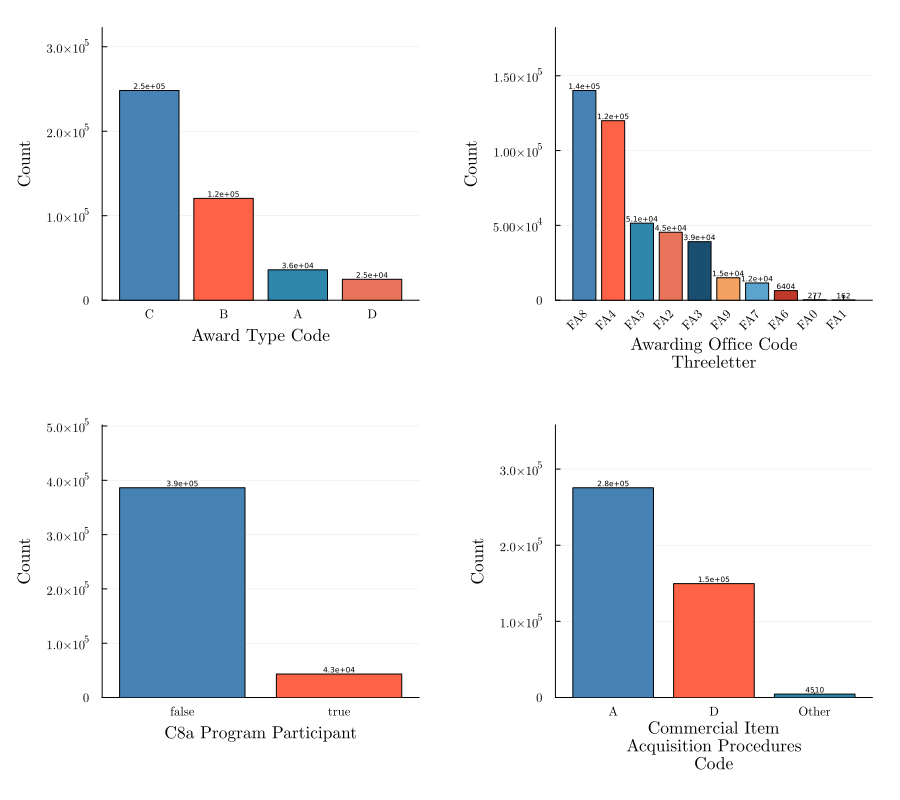

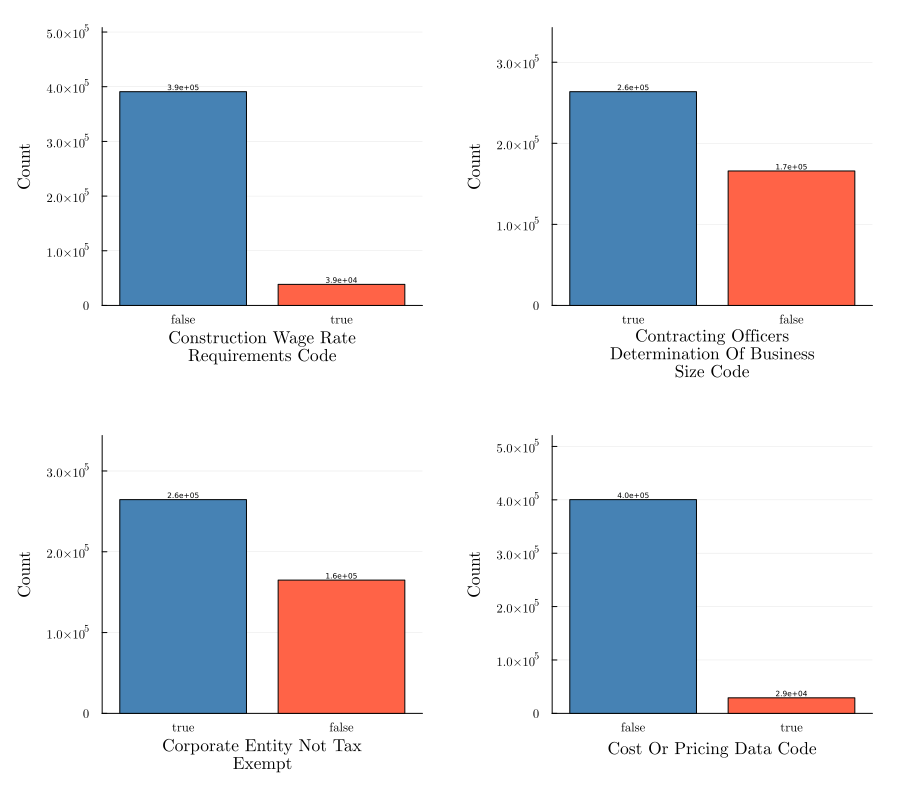

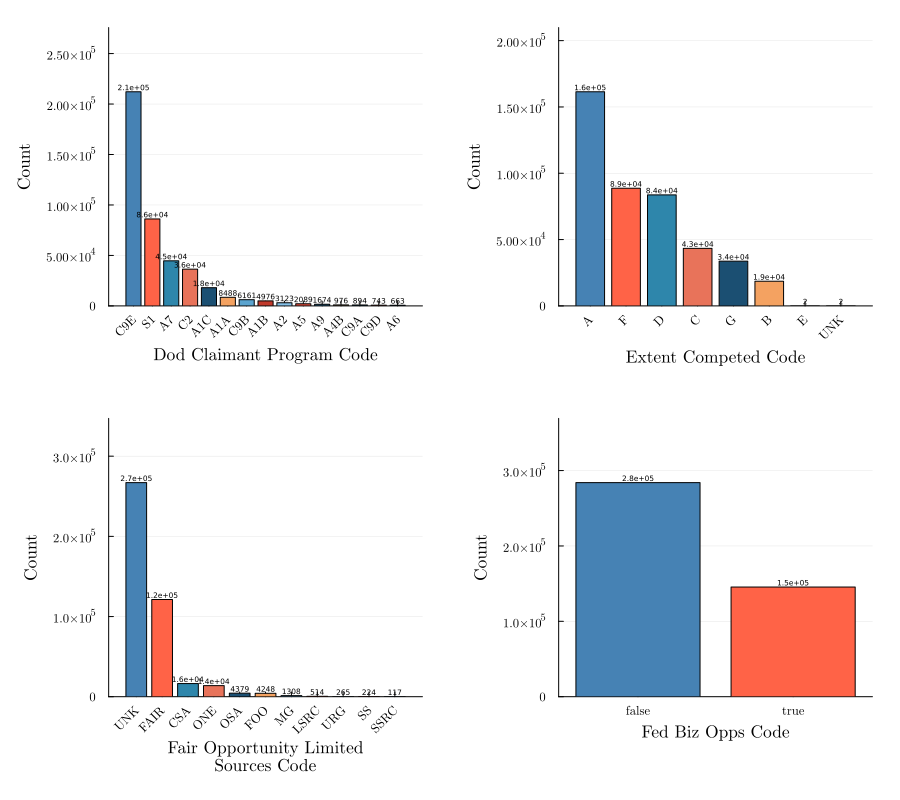

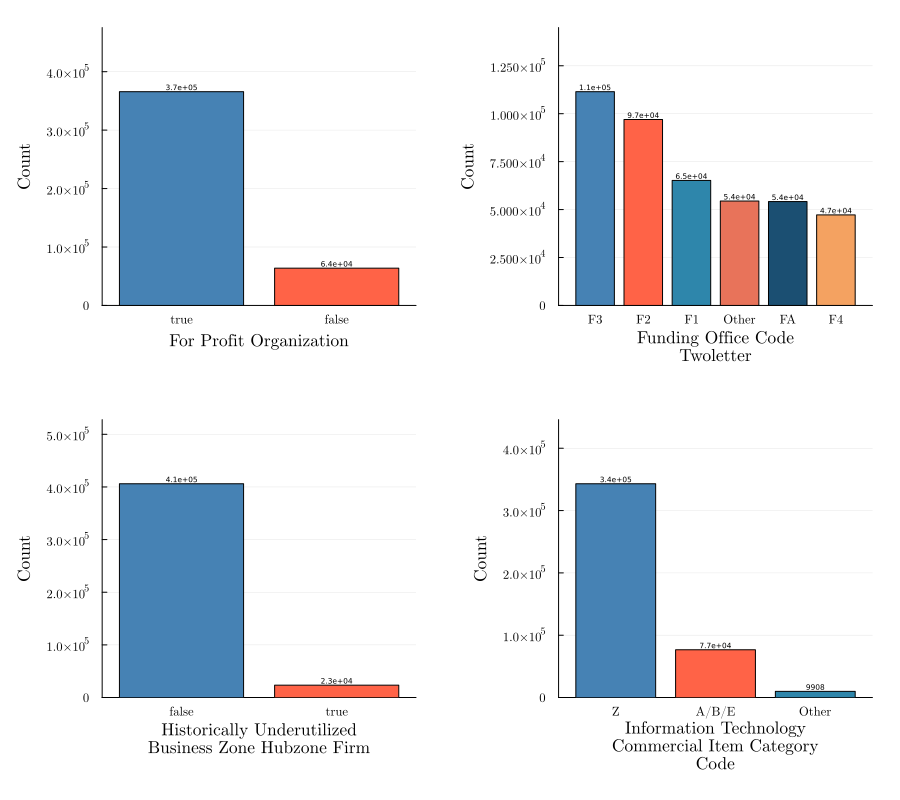

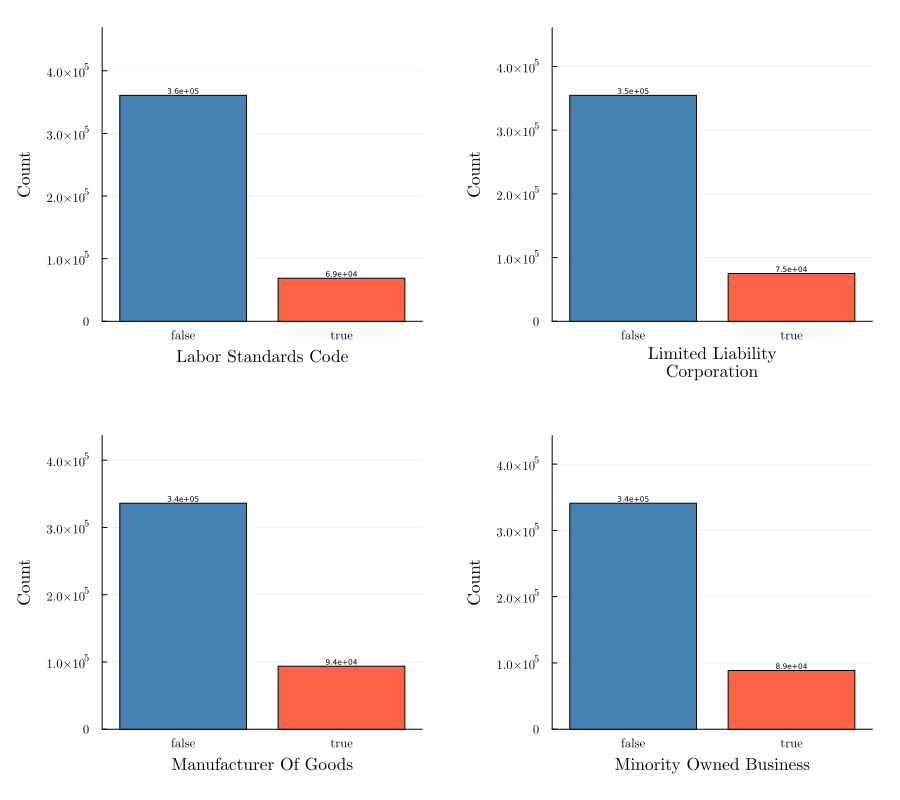

...

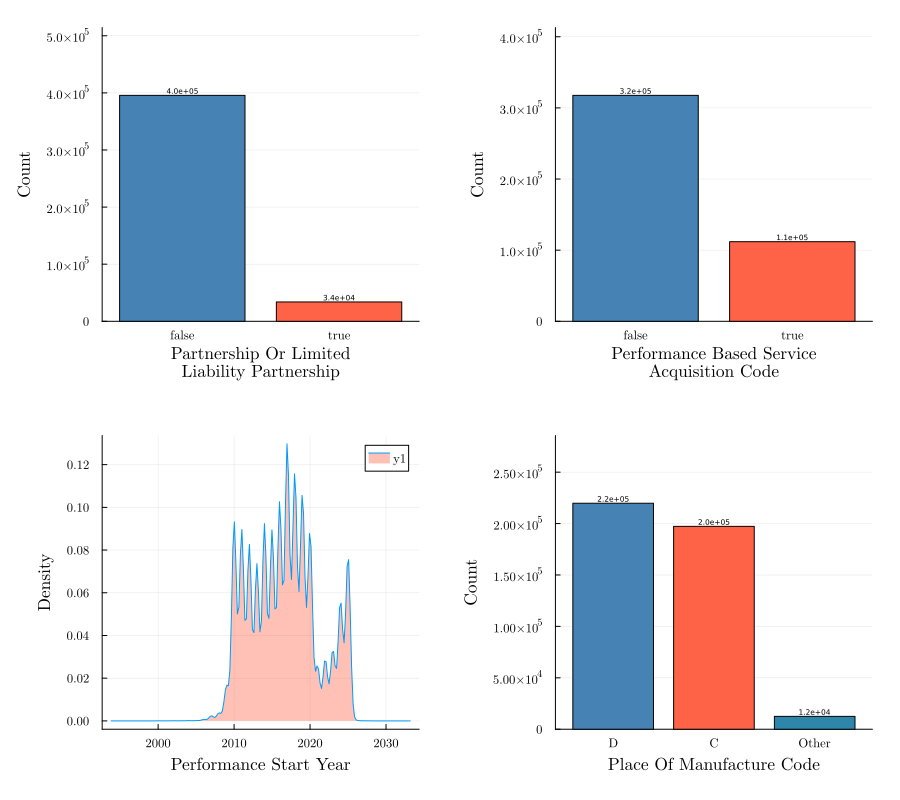

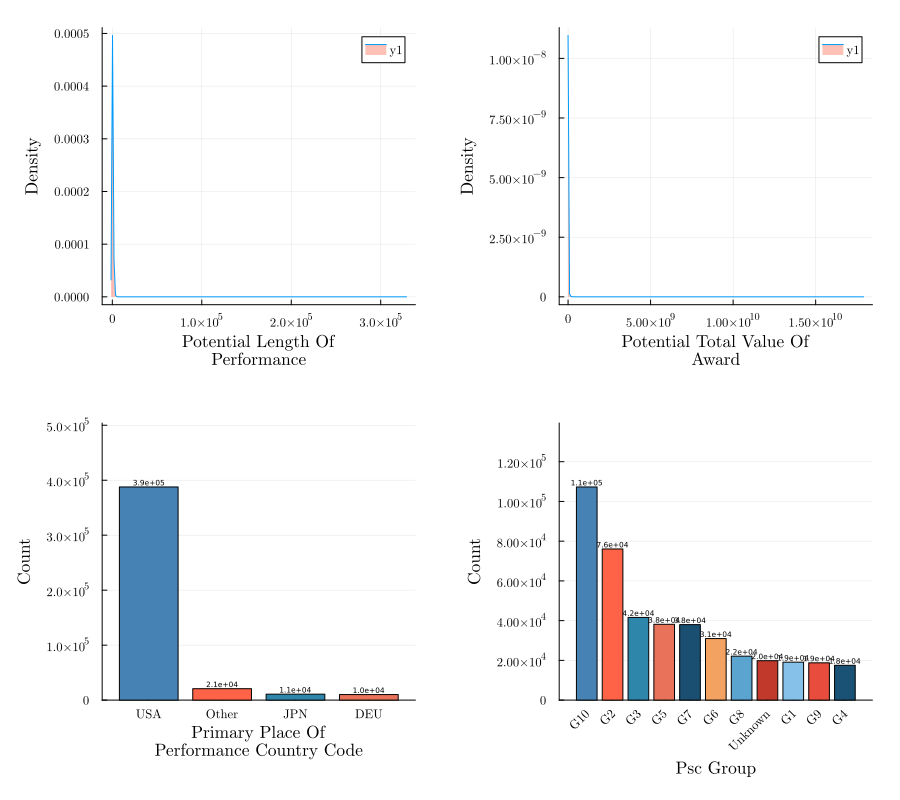

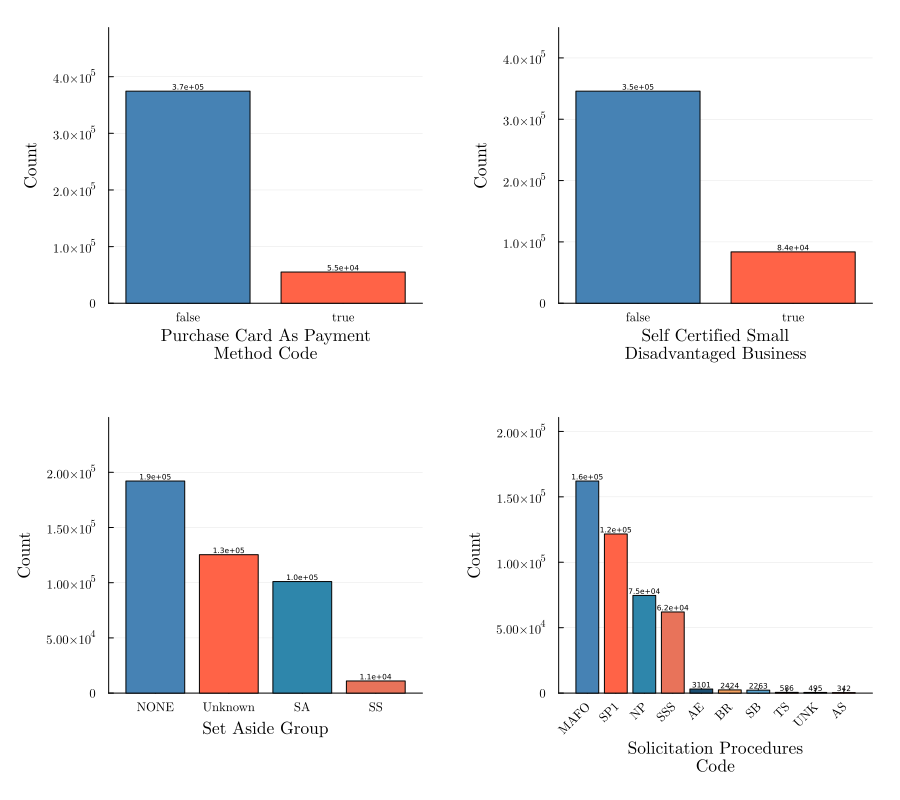

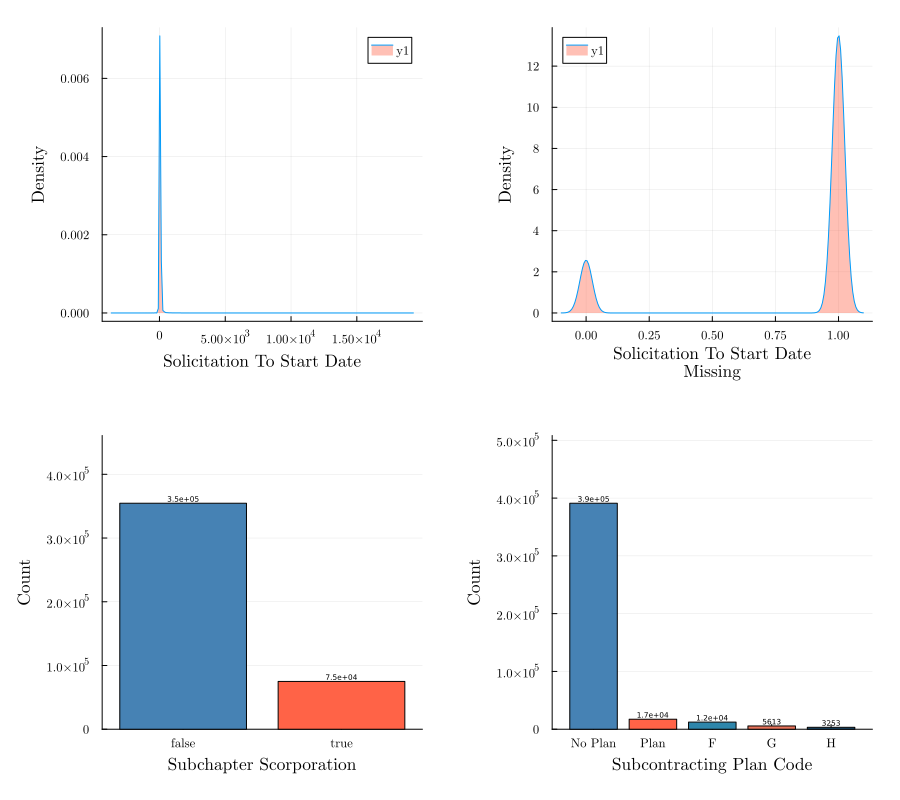

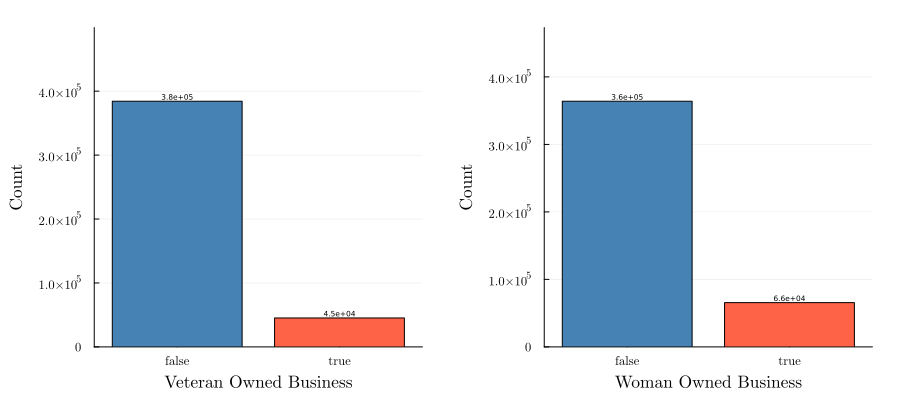

nothing

In [40]:
p = plot_distributions_pro(df_removed_poor_distros[!,2:end]) # Exclude the unique key for plotting;
display(p)

# Final Removals of Contract ID, 

In [41]:
# count number of rows that have 0 in potential total value of award
num_zero_awards = count(==(0), df_removed_poor_distros.potential_total_value_of_award)
println("Number of rows with 0 in potential_total_value_of_award: $num_zero_awards")
# count number of rosw that have less than 5$ in potential total value of award
num_low_awards = count(x -> x < 5, df_removed_poor_distros.potential_total_value_of_award)
println("Number of rows with less than 5 in potential_total_value_of_award: $num_low_awards")


Number of rows with 0 in potential_total_value_of_award: 0
Number of rows with less than 5 in potential_total_value_of_award: 210


In [42]:
#describe the distribution of potential total value of award
describe(df_removed_poor_distros.potential_total_value_of_award)

Summary Stats:
Length:         429517
Missing Count:  0
Mean:           2463282.202901
Std. Deviation: 72697212.381664
Minimum:        0.010000
1st Quartile:   14892.000000
Median:         47550.000000
3rd Quartile:   187385.600000
Maximum:        17902390303.410000
Type:           Float64


In [43]:
df_pre_final = filter(row -> row.potential_total_value_of_award > 0, df_removed_poor_distros)

println("Removed: ", nrow(df_removed_poor_distros) - nrow(df_pre_final), " rows")
println("Remaining: ", nrow(df_pre_final))

Removed: 0 rows
Remaining: 429517


In [44]:
df_pre_final

Row,contract_award_unique_key,award_type_code,awarding_office_code_threeletter,c8a_program_participant,commercial_item_acquisition_procedures_code,construction_wage_rate_requirements_code,contracting_officers_determination_of_business_size_code,corporate_entity_not_tax_exempt,cost_or_pricing_data_code,dod_claimant_program_code,extent_competed_code,fair_opportunity_limited_sources_code,fed_biz_opps_code,for_profit_organization,funding_office_code_twoletter,historically_underutilized_business_zone_hubzone_firm,information_technology_commercial_item_category_code,labor_standards_code,limited_liability_corporation,manufacturer_of_goods,minority_owned_business,naics_code_sector,number_of_actions,number_of_offers_received,organizational_type,other_than_full_and_open_competition_code,parent_award_group,parent_award_single_or_multiple_code,parent_award_type_code,partnership_or_limited_liability_partnership,performance_based_service_acquisition_code,performance_start_year,place_of_manufacture_code,potential_length_of_performance,potential_total_value_of_award,primary_place_of_performance_country_code,psc_group,purchase_card_as_payment_method_code,self_certified_small_disadvantaged_business,set_aside_group,solicitation_procedures_code,solicitation_to_start_date,solicitation_to_start_date_missing,subchapter_scorporation,subcontracting_plan_code,veteran_owned_business,woman_owned_business
,String,String,String,Bool,String,Bool,Bool,Bool,Bool,String,String,String,Bool,Bool,String,Bool,String,Bool,Bool,Bool,Bool,String,String,Int64,String,String,String,String,String,Bool,Bool,Int64,String,Int64,Float64,String,String,Bool,Bool,String,String,Int64,Int64,Bool,String,Bool,Bool
1,CONT_AWD_0001_9700_DADA1099D0053_9700,C,FA3,false,D,false,false,false,false,C2,A,FAIR,true,false,F2,false,Z,true,false,false,false,22,1,9,UNK,UNK,D,M,B,false,false,2000,C,8831,5.53216e7,USA,G6,false,false,NONE,MAFO,44,1,false,Plan,false,false
2,CONT_AWD_0001_9700_F0960402D0090_9700,C,FA8,false,D,false,false,true,true,C9E,C,UNK,false,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,33,1,1,CORPORATE NOT TAX EXEMPT,NS,D,S,B,false,false,2001,D,1653,22231.0,USA,G7,false,false,NONE,SSS,44,1,false,No Plan,false,false
3,CONT_AWD_0001_9700_F0960403D0090_9700,C,FA8,false,D,false,false,true,true,C9E,C,UNK,false,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,1,CORPORATE NOT TAX EXEMPT,NS,D,S,B,false,true,2002,C,2068,169650.0,USA,G6,false,false,NONE,SSS,44,1,false,Plan,false,false
4,CONT_AWD_0001_9700_F1962896D0038_9700,C,FA8,false,D,false,false,true,false,A7,A,UNK,false,true,F2,false,Z,false,false,true,false,33,1,2,CORPORATE NOT TAX EXEMPT,UNK,D,S,B,false,false,2000,D,3476,3.38761e7,USA,G4,false,false,NONE,NP,44,1,false,Plan,false,false
5,CONT_AWD_0001_9700_FA150010D0001_9700,C,FA8,false,D,false,false,true,true,C9E,A,FAIR,true,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,9,CORPORATE NOT TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,33000.0,USA,G1,false,false,NONE,MAFO,44,1,false,Plan,false,false
6,CONT_AWD_0001_9700_FA150010D0002_9700,C,FA8,false,D,false,false,true,true,C9E,A,FAIR,true,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,9,CORPORATE NOT TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,31836.0,USA,G1,false,false,NONE,MAFO,44,1,false,No Plan,false,false
7,CONT_AWD_0001_9700_FA150010D0003_9700,C,FA8,false,D,false,false,false,true,C9E,A,FAIR,true,false,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,true,false,54,1,9,CORPORATE TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,18160.5,USA,G1,false,false,NONE,MAFO,44,1,false,No Plan,false,false
8,CONT_AWD_0001_9700_FA150010D0004_9700,C,FA8,false,D,false,false,true,false,C9E,A,FAIR,true,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,9,CORPORATE NOT TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,32280.0,USA,G1,false,false,NONE,MAFO,44,1,false,No Plan,false,false
9,CONT_AWD_0001_9700_FA1500

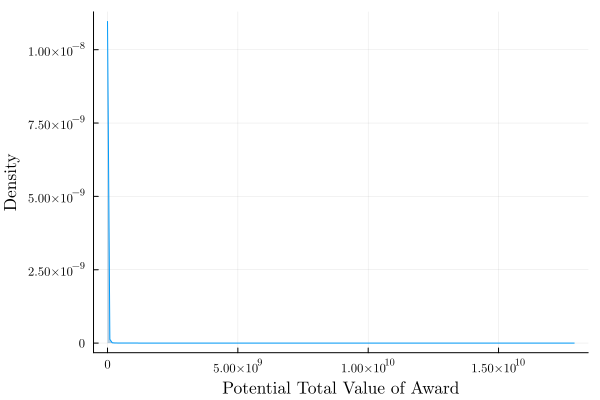

In [64]:
p = StatsPlots.density(df_pre_final.potential_total_value_of_award,
    xlabel = "Potential Total Value of Award",
    ylabel = "Density",
    label = false,
    fill = (0, 0.4, :steelblue))

In [68]:
gr()
StatsPlots.savefig(p, "figures/potential_total_value_of_award_density_plot.pdf")

"/Users/paola/Docs/dev/phantom_project/project 1 - estimating potential total value/ALL-COL-FINAL/figures/potential_total_value_of_award_density_plot.pdf"

In [45]:
using Parquet2

final_df = copy(df_pre_final) # Create a copy to preserve the original

final_df.log_award_amount = log10.(final_df.potential_total_value_of_award .+ 1) # Add 1 to avoid log(0)
final_df = select(final_df, Not(:potential_total_value_of_award, :contract_award_unique_key))
#Parquet2.writefile("05122026_df_final.parquet", final_df)

Row,award_type_code,awarding_office_code_threeletter,c8a_program_participant,commercial_item_acquisition_procedures_code,construction_wage_rate_requirements_code,contracting_officers_determination_of_business_size_code,corporate_entity_not_tax_exempt,cost_or_pricing_data_code,dod_claimant_program_code,extent_competed_code,fair_opportunity_limited_sources_code,fed_biz_opps_code,for_profit_organization,funding_office_code_twoletter,historically_underutilized_business_zone_hubzone_firm,information_technology_commercial_item_category_code,labor_standards_code,limited_liability_corporation,manufacturer_of_goods,minority_owned_business,naics_code_sector,number_of_actions,number_of_offers_received,organizational_type,other_than_full_and_open_competition_code,parent_award_group,parent_award_single_or_multiple_code,parent_award_type_code,partnership_or_limited_liability_partnership,performance_based_service_acquisition_code,performance_start_year,place_of_manufacture_code,potential_length_of_performance,primary_place_of_performance_country_code,psc_group,purchase_card_as_payment_method_code,self_certified_small_disadvantaged_business,set_aside_group,solicitation_procedures_code,solicitation_to_start_date,solicitation_to_start_date_missing,subchapter_scorporation,subcontracting_plan_code,veteran_owned_business,woman_owned_business,log_award_amount
,String,String,Bool,String,Bool,Bool,Bool,Bool,String,String,String,Bool,Bool,String,Bool,String,Bool,Bool,Bool,Bool,String,String,Int64,String,String,String,String,String,Bool,Bool,Int64,String,Int64,String,String,Bool,Bool,String,String,Int64,Int64,Bool,String,Bool,Bool,Float64
1,C,FA3,false,D,false,false,false,false,C2,A,FAIR,true,false,F2,false,Z,true,false,false,false,22,1,9,UNK,UNK,D,M,B,false,false,2000,C,8831,USA,G6,false,false,NONE,MAFO,44,1,false,Plan,false,false,7.74289
2,C,FA8,false,D,false,false,true,true,C9E,C,UNK,false,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,33,1,1,CORPORATE NOT TAX EXEMPT,NS,D,S,B,false,false,2001,D,1653,USA,G7,false,false,NONE,SSS,44,1,false,No Plan,false,false,4.34698
3,C,FA8,false,D,false,false,true,true,C9E,C,UNK,false,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,1,CORPORATE NOT TAX EXEMPT,NS,D,S,B,false,true,2002,C,2068,USA,G6,false,false,NONE,SSS,44,1,false,Plan,false,false,5.22956
4,C,FA8,false,D,false,false,true,false,A7,A,UNK,false,true,F2,false,Z,false,false,true,false,33,1,2,CORPORATE NOT TAX EXEMPT,UNK,D,S,B,false,false,2000,D,3476,USA,G4,false,false,NONE,NP,44,1,false,Plan,false,false,7.52989
5,C,FA8,false,D,false,false,true,true,C9E,A,FAIR,true,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,9,CORPORATE NOT TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,USA,G1,false,false,NONE,MAFO,44,1,false,Plan,false,false,4.51853
6,C,FA8,false,D,false,false,true,true,C9E,A,FAIR,true,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,9,CORPORATE NOT TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,USA,G1,false,false,NONE,MAFO,44,1,false,No Plan,false,false,4.50293
7,C,FA8,false,D,false,false,false,true,C9E,A,FAIR,true,false,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,true,false,54,1,9,CORPORATE TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,USA,G1,false,false,NONE,MAFO,44,1,false,No Plan,false,false,4.25915
8,C,FA8,false,D,false,false,true,false,C9E,A,FAIR,true,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,9,CORPORATE NOT TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,USA,G1,false,false,NONE,MAFO,44,1,false,No Plan,false,false,4.50895
9,C,FA8,false,D,false,false,true,false,C9E,A,FAIR,true,true,OTHER_FUNDING_OFFICE_CODE_TWOLETTER,false,Z,false,false,false,false,54,1,9,CORPORATE NOT TAX EXEMPT,UNK,D,M,B,false,true,2010,C,2008,USA,G1,false,false,NONE,MAFO,44,1,false,No Plan,false,false,4.4462
